In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

In [2]:
import pyspark

print("PySpark version:", pyspark.__version__)

PySpark version: 4.0.4


In [3]:
from pyspark.sql import SparkSession
from pyspark.sql import SparkSession
from pyspark.sql.functions import col, count, when, isnan, lit, to_timestamp
from pyspark.sql.types import DoubleType, IntegerType

In [5]:
import os


os.environ["PYSPARK_SUBMIT_ARGS"] = (
    "--driver-memory 8g pyspark-shell"
)

from pyspark.sql import SparkSession

spark = (
    SparkSession.builder
    .appName("NYC_Taxi_Trip_Duration")
    .master("local[*]")
    .config("spark.driver.memory", "8g")
    .config("spark.sql.shuffle.partitions", "16")
    .config("spark.default.parallelism", "8")
    .getOrCreate()
)

print("Spark version:", spark.version)
print(
    "JVM max heap (GB):",
    round(
        spark._jvm.java.lang.Runtime.getRuntime().maxMemory()
        / (1024**3),
        2
    )
)

Spark version: 4.0.4
JVM max heap (GB): 8.0


In [11]:
!unzip /kaggle/input/competitions/nyc-taxi-trip-duration/train.zip -d /kaggle/working/

Archive:  /kaggle/input/competitions/nyc-taxi-trip-duration/train.zip
  inflating: /kaggle/working/train.csv  


In [12]:
!unzip /kaggle/input/competitions/nyc-taxi-trip-duration/test.zip -d /kaggle/working/

Archive:  /kaggle/input/competitions/nyc-taxi-trip-duration/test.zip
  inflating: /kaggle/working/test.csv  


In [13]:
!ls /kaggle/working/

test.csv  train.csv


In [14]:
df_train=spark.read \
    .option("header", "true") \
    .option("inferSchema", "true") \
    .csv("/kaggle/working/train.csv")

In [15]:
df_test =spark.read \
    .option("header", "true") \
    .option("inferSchema", "true") \
    .csv("/kaggle/working/test.csv")

In [16]:
df_train.printSchema()

root
 |-- id: string (nullable = true)
 |-- vendor_id: integer (nullable = true)
 |-- pickup_datetime: timestamp (nullable = true)
 |-- dropoff_datetime: timestamp (nullable = true)
 |-- passenger_count: integer (nullable = true)
 |-- pickup_longitude: double (nullable = true)
 |-- pickup_latitude: double (nullable = true)
 |-- dropoff_longitude: double (nullable = true)
 |-- dropoff_latitude: double (nullable = true)
 |-- store_and_fwd_flag: string (nullable = true)
 |-- trip_duration: integer (nullable = true)



In [17]:
# ============================================================
# CELL 1 — Feature engineering + parquet (OOM-safe)
# Writes: prepared/train_vec, val_vec, test_vec, train_wide, test_wide
# ============================================================
import time
import math
import numpy as np
from pathlib import Path
from pyspark.sql import functions as F
from pyspark.ml.feature import VectorAssembler, StringIndexer
from pyspark.ml import Pipeline

PREP = Path("/kaggle/working/prepared")
TWO_PI = 2 * math.pi

NYC_BOUNDS       = {"lon": (-74.3, -73.7),   "lat": (40.4, 40.9)}
JFK_BOUNDS       = {"lon": (-73.82, -73.74), "lat": (40.62, 40.68)}
LGA_BOUNDS       = {"lon": (-73.90, -73.84), "lat": (40.75, 40.80)}
MANHATTAN_BOUNDS = {"lon": (-74.02, -73.90),"lat": (40.70, 40.88)}

MAX_DUR_SEC = 86400
MIN_DUR_SEC = 30

FEATURE_COLS = [
    "vendor_id", "passenger_count",
    "pickup_longitude", "pickup_latitude",
    "dropoff_longitude", "dropoff_latitude",
    "store_and_fwd_flag_y",
    "pickup_hour", "pickup_dayofweek", "pickup_month",
    "is_weekend", "is_rush_hour", "is_late_night",
    "pickup_hour_sin", "pickup_hour_cos",
    "pickup_dow_sin",  "pickup_dow_cos",
    "pickup_month_sin","pickup_month_cos",
    "haversine_km", "distance_bin",
    "is_jfk_pickup", "is_lga_pickup", "is_airport_pickup",
    "is_manhattan", "slow_trip_indicator",
    "is_group_trip", "vendor_rush", "vendor_x_group_idx",
]

def add_temporal(df):
    df = df.withColumn("pickup_datetime", F.to_timestamp("pickup_datetime"))
    df = df.withColumn("pickup_hour",      F.hour("pickup_datetime"))
    df = df.withColumn("pickup_dayofweek", F.dayofweek("pickup_datetime"))
    df = df.withColumn("pickup_month",     F.month("pickup_datetime"))
    df = df.withColumn("is_weekend",
        F.when(F.col("pickup_dayofweek").isin([1,7]),1).otherwise(0))
    df = df.withColumn("is_rush_hour",
        F.when(F.col("pickup_hour").between(7,9) |
               F.col("pickup_hour").between(17,19),1).otherwise(0))
    df = df.withColumn("is_late_night",
        F.when((F.col("pickup_hour")>=22) | (F.col("pickup_hour")<=4),1).otherwise(0))
    return df

def add_cyclical(df):
    df = df.withColumn("pickup_hour_sin",
        F.sin(F.lit(TWO_PI) * F.col("pickup_hour") / F.lit(24.0)))
    df = df.withColumn("pickup_hour_cos",
        F.cos(F.lit(TWO_PI) * F.col("pickup_hour") / F.lit(24.0)))
    dow_norm = (F.col("pickup_dayofweek") - F.lit(1)).cast("double")
    df = df.withColumn("pickup_dow_sin",
        F.sin(F.lit(TWO_PI) * dow_norm / F.lit(7.0)))
    df = df.withColumn("pickup_dow_cos",
        F.cos(F.lit(TWO_PI) * dow_norm / F.lit(7.0)))
    month_norm = (F.col("pickup_month") - F.lit(1)).cast("double")
    df = df.withColumn("pickup_month_sin",
        F.sin(F.lit(TWO_PI) * month_norm / F.lit(12.0)))
    df = df.withColumn("pickup_month_cos",
        F.cos(F.lit(TWO_PI) * month_norm / F.lit(12.0)))
    return df

def add_spatial(df):
    lon1, lat1 = F.radians("pickup_longitude"),  F.radians("pickup_latitude")
    lon2, lat2 = F.radians("dropoff_longitude"), F.radians("dropoff_latitude")
    a = F.sin((lat2-lat1)/2)**2 + F.cos(lat1)*F.cos(lat2)*F.sin((lon2-lon1)/2)**2
    df = df.withColumn("haversine_km", F.lit(2*6371.0)*F.atan2(F.sqrt(a), F.sqrt(1-a)))
    df = df.withColumn("distance_bin", F.floor(F.col("haversine_km")).cast("int"))
    df = df.withColumn("is_jfk_pickup",
        F.when(F.col("pickup_longitude").between(*JFK_BOUNDS["lon"]) &
               F.col("pickup_latitude").between(*JFK_BOUNDS["lat"]),1).otherwise(0))
    df = df.withColumn("is_lga_pickup",
        F.when(F.col("pickup_longitude").between(*LGA_BOUNDS["lon"]) &
               F.col("pickup_latitude").between(*LGA_BOUNDS["lat"]),1).otherwise(0))
    df = df.withColumn("is_airport_pickup", F.greatest("is_jfk_pickup","is_lga_pickup"))
    df = df.withColumn("is_manhattan",
        F.when(F.col("pickup_longitude").between(*MANHATTAN_BOUNDS["lon"]) &
               F.col("pickup_latitude").between(*MANHATTAN_BOUNDS["lat"]),1).otherwise(0))
    df = df.withColumn("slow_trip_indicator",
        F.when((F.col("is_rush_hour")==1) & (F.col("haversine_km")<3),1).otherwise(0))
    return df

def add_interactions(df):
    df = df.withColumn("is_group_trip",
        F.when(F.col("passenger_count")>=2,1).otherwise(0))
    df = df.withColumn("vendor_x_group",
        F.concat(F.col("vendor_id").cast("string"), F.lit("_"),
                 F.col("is_group_trip").cast("string")))
    df = df.withColumn("vendor_rush",
        F.when((F.col("vendor_id")==2) & (F.col("is_rush_hour")==1),1).otherwise(0))
    return df

def build_features(df):
    df = add_temporal(df)
    df = add_cyclical(df)
    df = add_spatial(df)
    df = df.withColumn("store_and_fwd_flag_y",
        F.when(F.col("store_and_fwd_flag")=="Y",1).otherwise(0))
    df = df.drop("store_and_fwd_flag")
    df = df.withColumn("passenger_count",
        F.when(F.col("passenger_count")>6,6).otherwise(F.col("passenger_count")))
    df = add_interactions(df)
    return df

# ---- Load ----
print("\n=== Loading CSVs ===")
df_train_raw = spark.read.option("header", True).option("inferSchema", True) \
    .csv("/kaggle/working/train.csv")
df_test_raw = spark.read.option("header", True).option("inferSchema", True) \
    .csv("/kaggle/working/test.csv")
print(f"  train: {df_train_raw.count():,}")
print(f"  test : {df_test_raw.count():,}")

# ---- Build features ----
print("\n=== Building features ===")
t0 = time.time()
df_train = build_features(df_train_raw).drop("dropoff_datetime")
df_test  = build_features(df_test_raw)
print(f"  done in {time.time()-t0:.1f}s")

# ---- Clean train only ----
print("\n=== Cleaning train ===")
before = df_train.count()
df_train = df_train.filter(
    (F.col("trip_duration") > 0) &
    (F.col("trip_duration").between(MIN_DUR_SEC, MAX_DUR_SEC)) &
    (F.col("passenger_count") > 0) &
    (F.col("haversine_km") > 0)
).withColumn("log_trip_duration", F.log1p("trip_duration"))
after = df_train.count()
print(f"  {before:,} → {after:,} (removed {before-after:,})")

# ---- Time split ----
print("\n=== Time-based split ===")
ts = F.lit("2016-06-01 00:00:00").cast("timestamp")
train_part = df_train.filter(F.col("pickup_datetime") < ts)
valid_part = df_train.filter(F.col("pickup_datetime") >= ts)
n_tr = train_part.count()
n_va = valid_part.count()
print(f"  train_part: {n_tr:,}")
print(f"  valid_part: {n_va:,}")

# ---- Persist ----
train_part = train_part.persist(); train_part.count()
valid_part = valid_part.persist(); valid_part.count()
df_test    = df_test.persist();    df_test.count()

# ---- Fit pipeline ----
print("\n=== Fitting pipeline ===")
indexer = StringIndexer(inputCol="vendor_x_group", outputCol="vendor_x_group_idx",
                        handleInvalid="keep")
assembler = VectorAssembler(inputCols=FEATURE_COLS, outputCol="features",
                            handleInvalid="keep")
pipeline = Pipeline(stages=[indexer, assembler])
t0 = time.time()
pipeline_model = pipeline.fit(train_part)
print(f"  fit in {time.time()-t0:.1f}s")

# ---- Transform + write ----
print("\n=== Writing parquet ===")
for name, df in [("train_vec", train_part),
                 ("val_vec",   valid_part),
                 ("test_vec",  df_test)]:
    t0 = time.time()
    (pipeline_model.transform(df)
     .select("id", "features",
             *(["trip_duration", "log_trip_duration"]
               if "trip_duration" in df.columns else []))
     .write.mode("overwrite").parquet(str(PREP / name)))
    print(f"  ✅ {name} ({time.time()-t0:.1f}s)")

# ---- Wide format (raw columns, for debugging) ----
for name, df in [("train_wide", train_part),
                 ("val_wide",   valid_part),
                 ("test_wide",  df_test)]:
    cols = ["id"] + FEATURE_COLS
    if "trip_duration" in df.columns:
        cols += ["trip_duration", "log_trip_duration"]
    (pipeline_model.transform(df).select(*cols)
     .write.mode("overwrite").parquet(str(PREP / name)))
    print(f"  ✅ {name}")

# ---- Save pipeline ----
pipeline_model.write().overwrite().save(str(PREP / "pipeline"))

# ---- Unpersist ----
train_part.unpersist(); valid_part.unpersist(); df_test.unpersist()

# ---- Verify ----
print("\n=== VERIFY ===")
train_chk = spark.read.parquet(str(PREP / "train_vec"))
val_chk   = spark.read.parquet(str(PREP / "val_vec"))
test_chk  = spark.read.parquet(str(PREP / "test_vec"))
print(f"  train_vec : {train_chk.count():,}")
print(f"  val_vec   : {val_chk.count():,}")
print(f"  test_vec  : {test_chk.count():,}")
assert test_chk.count() == df_test_raw.count(), "test rows lost!"
print("✅ CELL 1 DONE — Data prepared.")


=== Loading CSVs ===


  train: 1,458,644
  test : 625,134

=== Building features ===
  done in 1.6s

=== Cleaning train ===


  1,458,644 → 1,449,273 (removed 9,371)

=== Time-based split ===


26/10/23 12:13:17 WARN SparkStringUtils: Truncated the string representation of a plan since it was too large. This behavior can be adjusted by setting 'spark.sql.debug.maxToStringFields'.


  train_part: 1,216,551
  valid_part: 232,722


...

  ✅ val_vec (1.7s)


  ✅ test_vec (4.0s)


  ✅ train_wide


  ✅ val_wide


  ✅ test_wide

=== VERIFY ===
  train_vec : 1,216,551
  val_vec   : 232,722
  test_vec  : 625,134
✅ CELL 1 DONE — Data prepared.


In [18]:
# ============================================================
# CELL 2 — Train 4 base models, save to disk
# ============================================================
import time
import os
from pyspark.sql import functions as F
from pyspark.ml.regression import (
    DecisionTreeRegressor, RandomForestRegressor, GBTRegressor,
)
from pyspark.ml.evaluation import RegressionEvaluator

PREP   = "/kaggle/working/prepared"
MODELS = "/kaggle/working/models"
os.makedirs(MODELS, exist_ok=True)

# ---- Load parquet ----
print("\n=== Loading prepared data ===")
train_df = spark.read.parquet(f"{PREP}/train_vec").persist()
valid_df = spark.read.parquet(f"{PREP}/val_vec").persist()
n_train = train_df.count()
n_valid = valid_df.count()
print(f"  train: {n_train:,}")
print(f"  valid: {n_valid:,}")

eval_rmse = RegressionEvaluator(
    labelCol="log_trip_duration", predictionCol="prediction", metricName="rmse")

def train_and_save(model, name, path):
    """Fit, evaluate, save."""
    t0 = time.time()
    fitted = model.fit(train_df)
    train_t = time.time() - t0

    t0 = time.time()
    rmsle = eval_rmse.evaluate(fitted.transform(valid_df))
    pred_t = time.time() - t0

    fitted.write().overwrite().save(path)
    print(f"  ✅ {name:15s} RMSLE={rmsle:.4f} | "
          f"train={train_t:.0f}s | pred={pred_t:.1f}s")
    return fitted, {"name": name, "rmsle": rmsle, "train_t": train_t}

# ---- 1. Decision Tree ----
print("\n=== Training ===")
model_dt, m_dt = train_and_save(
    DecisionTreeRegressor(
        featuresCol="features", labelCol="log_trip_duration",
        maxDepth=10, maxBins=64, seed=42),
    "DecisionTree", f"{MODELS}/dt",
)

# ---- 2. Random Forest ----
model_rf, m_rf = train_and_save(
    RandomForestRegressor(
        featuresCol="features", labelCol="log_trip_duration",
        numTrees=50, maxDepth=10, maxBins=64, seed=42),
    "RandomForest", f"{MODELS}/rf",
)

# ---- 3. GBT (shallow) ----
model_gbt, m_gbt = train_and_save(
    GBTRegressor(
        featuresCol="features", labelCol="log_trip_duration",
        maxIter=50, maxDepth=6, stepSize=0.1,
        subsamplingRate=0.8, seed=42),
    "GBT", f"{MODELS}/gbt",
)

# ---- 4. GBT (deep) ----
model_gbt2, m_gbt2 = train_and_save(
    GBTRegressor(
        featuresCol="features", labelCol="log_trip_duration",
        maxIter=100, maxDepth=8, stepSize=0.05,
        subsamplingRate=0.8, seed=42),
    "GBT-deep", f"{MODELS}/gbt_deep",
)

train_df.unpersist(); valid_df.unpersist()
print("\n✅ CELL 2 DONE — Models saved.")
print(f"   Models in: {MODELS}/")
for f in sorted(os.listdir(MODELS)):
    print(f"     {f}")


=== Loading prepared data ===


  train: 1,216,551
  valid: 232,722

=== Training ===


  ✅ DecisionTree    RMSLE=0.4373 | train=12s | pred=0.7s


26/10/23 12:15:17 WARN DAGScheduler: Broadcasting large task binary with size 1120.2 KiB
26/10/23 12:15:37 WARN DAGScheduler: Broadcasting large task binary with size 2.2 MiB
26/10/23 12:15:59 WARN DAGScheduler: Broadcasting large task binary with size 4.2 MiB
26/10/23 12:16:33 WARN DAGScheduler: Broadcasting large task binary with size 1229.3 KiB
26/10/23 12:16:35 WARN DAGScheduler: Broadcasting large task binary with size 8.3 MiB
26/10/23 12:17:09 WARN DAGScheduler: Broadcasting large task binary with size 2.3 MiB
26/10/23 12:17:15 WARN TaskSetManager: Stage 142 contains a task of very large size (1119 KiB). The maximum recommended task size is 1000 KiB.


  ✅ RandomForest    RMSLE=0.4345 | train=170s | pred=2.8s


  ✅ GBT             RMSLE=0.4114 | train=132s | pred=1.3s


26/10/23 12:20:51 WARN DAGScheduler: Broadcasting large task binary with size 1004.2 KiB
26/10/23 12:20:52 WARN DAGScheduler: Broadcasting large task binary with size 1010.2 KiB
26/10/23 12:20:52 WARN DAGScheduler: Broadcasting large task binary with size 1010.7 KiB
26/10/23 12:20:53 WARN DAGScheduler: Broadcasting large task binary with size 1011.8 KiB
26/10/23 12:20:53 WARN DAGScheduler: Broadcasting large task binary with size 1012.5 KiB
26/10/23 12:20:53 WARN DAGScheduler: Broadcasting large task binary with size 1014.9 KiB
26/10/23 12:20:54 WARN DAGScheduler: Broadcasting large task binary with size 1019.6 KiB
26/10/23 12:20:54 WARN DAGScheduler: Broadcasting large task binary with size 1029.0 KiB
26/10/23 12:20:55 WARN DAGScheduler: Broadcasting large task binary with size 1047.5 KiB
26/10/23 12:20:55 WARN DAGScheduler: Broadcasting large task binary with size 1053.0 KiB
26/10/23 12:20:56 WARN DAGScheduler: Broadcasting large task binary with size 1053.5 KiB
26/10/23 12:20:56 WAR

  ✅ GBT-deep        RMSLE=0.4005 | train=439s | pred=3.0s

✅ CELL 2 DONE — Models saved.
   Models in: /kaggle/working/models/
     dt
     gbt
     gbt_deep
     rf



=== Loading models ===


  ✅ all 4 loaded


  valid: 232,722


  test : 625,134

=== Collecting predictions ===


  done in 12.1s

=== Ensemble search ===

=== All strategies ranked ===
 rank                strategy  rmsle  mae_sec  median_err
    1     individual:GBT-deep 0.4005    324.7       127.6
    2           weighted:all4 0.4005    324.7       127.6
    3    weighted:rf+gbt+gbt2 0.4005    324.7       127.6
    4        weighted:rf+gbt2 0.4005    324.7       127.6
    5         simple:gbt+gbt2 0.4033    327.0       129.5
    6      simple:rf+gbt+gbt2 0.4090    332.2       131.3
    7          simple:rf+gbt2 0.4109    334.4       131.4
    8          individual:GBT 0.4114    334.3       135.3
    9             simple:all4 0.4132    336.4       133.2
   10 individual:RandomForest 0.4345    355.8       143.9
   11 individual:DecisionTree 0.4373    358.6       146.8

🏆 Best: individual:GBT-deep


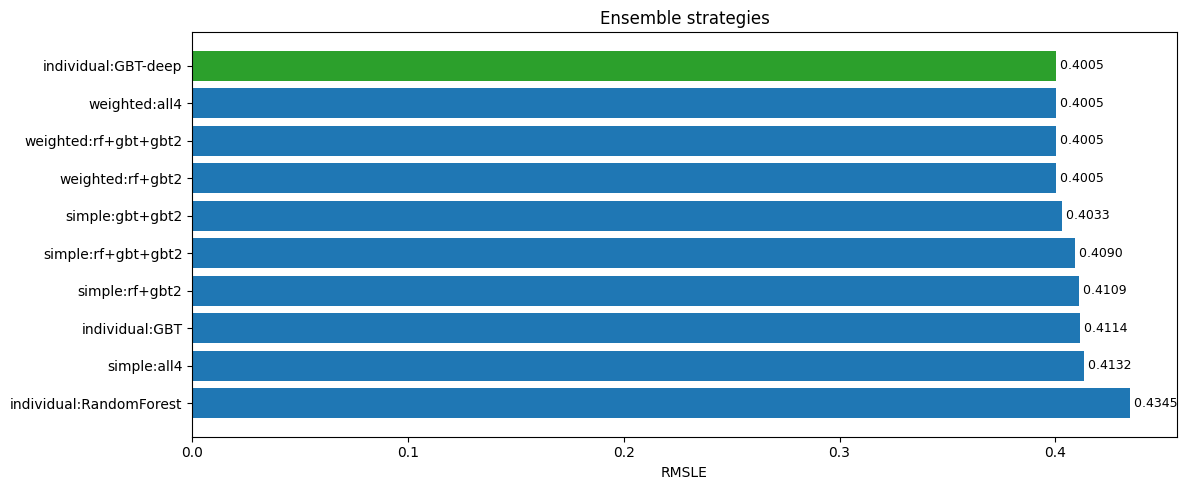


=== Generating test predictions ===
  ready in 0.9s



✅ Saved: /kaggle/working/submission_ensemble.csv
   rows: 625,134 | unique ids: 625,134

Prediction stats:
count    625134.0
mean        799.1
std         573.1
min          22.0
25%         404.7
50%         645.9
75%        1021.3
max        7249.6

✅ CELL 3 DONE — Submission ready!


In [19]:
# ============================================================
# CELL 3 — Ensemble + Submission
# ============================================================
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pyspark.sql import functions as F
from pyspark.ml.regression import (
    DecisionTreeRegressionModel, RandomForestRegressionModel,
    GBTRegressionModel,
)

PREP   = "/kaggle/working/prepared"
MODELS = "/kaggle/working/models"
MAX_SEC = 86400.0

# ---- Load models ----
print("\n=== Loading models ===")
model_dt   = DecisionTreeRegressionModel.load(f"{MODELS}/dt")
model_rf   = RandomForestRegressionModel.load(f"{MODELS}/rf")
model_gbt  = GBTRegressionModel.load(f"{MODELS}/gbt")
model_gbt2 = GBTRegressionModel.load(f"{MODELS}/gbt_deep")
print("  ✅ all 4 loaded")

# ---- Load data ----
valid_df = spark.read.parquet(f"{PREP}/val_vec").persist()
test_df  = spark.read.parquet(f"{PREP}/test_vec").persist()
print(f"  valid: {valid_df.count():,}")
print(f"  test : {test_df.count():,}")

# ---- Collect predictions on valid ----
def get_preds(model):
    return model.transform(valid_df).select(
        "id",
        F.col("prediction").alias("pred_log"),
        F.col("trip_duration").alias("true_sec"),
        F.col("log_trip_duration").alias("true_log"),
    ).toPandas()

print("\n=== Collecting predictions ===")
t0 = time.time()
p_dt   = get_preds(model_dt)
p_rf   = get_preds(model_rf)
p_gbt  = get_preds(model_gbt)
p_gbt2 = get_preds(model_gbt2)
print(f"  done in {time.time()-t0:.1f}s")

y_log = p_dt["true_log"].values.astype(np.float64)
y_sec = p_dt["true_sec"].values.astype(np.float64)

def rmsle(p): return float(np.sqrt(np.mean((y_log - p)**2)))
def mae_s(p): return float(np.mean(np.abs(y_sec - np.expm1(p))))

individual = {
    "DecisionTree": p_dt["pred_log"].values,
    "RandomForest": p_rf["pred_log"].values,
    "GBT":          p_gbt["pred_log"].values,
    "GBT-deep":     p_gbt2["pred_log"].values,
}

# ---- Ensemble search ----
print("\n=== Ensemble search ===")
strategies = {f"individual:{n}": p for n, p in individual.items()}
strategies["simple:all4"]        = sum(individual.values())/4
strategies["simple:rf+gbt2"]     = (individual["RandomForest"] + individual["GBT-deep"])/2
strategies["simple:gbt+gbt2"]    = (individual["GBT"] + individual["GBT-deep"])/2
strategies["simple:rf+gbt+gbt2"] = (individual["RandomForest"]+individual["GBT"]+individual["GBT-deep"])/3

# weighted pair
best_pair = {"rmsle": 1e9, "w_rf": 0, "w_gbt2": 0}
for w_rf in np.arange(0, 1.001, 0.05):
    p = w_rf*individual["RandomForest"] + (1-w_rf)*individual["GBT-deep"]
    r = rmsle(p)
    if r < best_pair["rmsle"]:
        best_pair = {"rmsle": r, "w_rf": w_rf, "w_gbt2": 1-w_rf}
strategies["weighted:rf+gbt2"] = (
    best_pair["w_rf"]*individual["RandomForest"]
    + best_pair["w_gbt2"]*individual["GBT-deep"]
)

# weighted triple
best_triple = {"rmsle": 1e9, "w": (0,0,0)}
for w_rf in np.arange(0, 1.001, 0.1):
    for w_gbt in np.arange(0, 1.001 - w_rf, 0.1):
        w_gbt2 = 1 - w_rf - w_gbt
        if w_gbt2 < 0: continue
        p = (w_rf*individual["RandomForest"] + w_gbt*individual["GBT"]
             + w_gbt2*individual["GBT-deep"])
        r = rmsle(p)
        if r < best_triple["rmsle"]:
            best_triple = {"rmsle": r, "w": (w_rf, w_gbt, w_gbt2)}
w_rf, w_gbt, w_gbt2 = best_triple["w"]
strategies["weighted:rf+gbt+gbt2"] = (
    w_rf*individual["RandomForest"] + w_gbt*individual["GBT"]
    + w_gbt2*individual["GBT-deep"]
)

# weighted quad
best_quad = {"rmsle": 1e9, "w": (0,0,0,0)}
for w_dt in np.arange(0, 0.21, 0.1):
    for w_rf in np.arange(0, 1.001-w_dt, 0.1):
        for w_gbt in np.arange(0, 1.001-w_dt-w_rf, 0.1):
            w_gbt2 = 1 - w_dt - w_rf - w_gbt
            if w_gbt2 < 0: continue
            p = (w_dt*individual["DecisionTree"] + w_rf*individual["RandomForest"]
                 + w_gbt*individual["GBT"] + w_gbt2*individual["GBT-deep"])
            r = rmsle(p)
            if r < best_quad["rmsle"]:
                best_quad = {"rmsle": r, "w": (w_dt, w_rf, w_gbt, w_gbt2)}
w_dt, w_rf, w_gbt, w_gbt2 = best_quad["w"]
strategies["weighted:all4"] = (
    w_dt*individual["DecisionTree"] + w_rf*individual["RandomForest"]
    + w_gbt*individual["GBT"] + w_gbt2*individual["GBT-deep"]
)

# ---- Results table ----
rows = []
for name, p in strategies.items():
    rows.append({
        "strategy": name,
        "rmsle": rmsle(p),
        "mae_sec": mae_s(p),
        "median_err": float(np.median(np.abs(y_sec - np.expm1(p)))),
    })
df_strat = pd.DataFrame(rows).sort_values("rmsle").reset_index(drop=True)
df_strat["rank"] = range(1, len(df_strat)+1)
df_strat["rmsle"] = df_strat["rmsle"].round(4)
df_strat["mae_sec"] = df_strat["mae_sec"].round(1)
df_strat["median_err"] = df_strat["median_err"].round(1)

pd.set_option("display.max_rows", None)
pd.set_option("display.width", 200)
print("\n=== All strategies ranked ===")
print(df_strat[["rank","strategy","rmsle","mae_sec","median_err"]].to_string(index=False))

best_name = df_strat.iloc[0]["strategy"]
print(f"\n🏆 Best: {best_name}")

# ---- Plot ----
fig, ax = plt.subplots(figsize=(12, 5))
top = df_strat.head(10)
colors = ["#2ca02c" if i==0 else "#1f77b4" for i in range(len(top))]
bars = ax.barh(top["strategy"], top["rmsle"], color=colors)
ax.set_xlabel("RMSLE")
ax.set_title("Ensemble strategies")
ax.invert_yaxis()
for b, v in zip(bars, top["rmsle"]):
    ax.text(v, b.get_y()+b.get_height()/2, f" {v:.4f}", va="center", fontsize=9)
plt.tight_layout()
plt.show()

# ---- Test predictions ----
print("\n=== Generating test predictions ===")
def test_pred(model, alias):
    return model.transform(test_df).select("id", F.col("prediction").alias(alias))

t0 = time.time()
test_joined = (
    test_pred(model_dt,   "pred_dt")
    .join(test_pred(model_rf,   "pred_rf"),   "id")
    .join(test_pred(model_gbt,  "pred_gbt"),  "id")
    .join(test_pred(model_gbt2, "pred_gbt2"), "id")
)
print(f"  ready in {time.time()-t0:.1f}s")

# ---- Ensemble expression ----
def build_expr(name):
    if name.startswith("individual:"):
        m = name.split(":")[1]
        cmap = {"DecisionTree":"pred_dt","RandomForest":"pred_rf",
                "GBT":"pred_gbt","GBT-deep":"pred_gbt2"}
        return F.col(cmap[m])
    if name == "simple:all4":
        return (F.col("pred_dt")+F.col("pred_rf")+F.col("pred_gbt")+F.col("pred_gbt2"))/4.0
    if name == "simple:rf+gbt2":
        return (F.col("pred_rf")+F.col("pred_gbt2"))/2.0
    if name == "simple:gbt+gbt2":
        return (F.col("pred_gbt")+F.col("pred_gbt2"))/2.0
    if name == "simple:rf+gbt+gbt2":
        return (F.col("pred_rf")+F.col("pred_gbt")+F.col("pred_gbt2"))/3.0
    if name == "weighted:rf+gbt2":
        return best_pair["w_rf"]*F.col("pred_rf") + best_pair["w_gbt2"]*F.col("pred_gbt2")
    if name == "weighted:rf+gbt+gbt2":
        return w_rf*F.col("pred_rf") + w_gbt*F.col("pred_gbt") + w_gbt2*F.col("pred_gbt2")
    if name == "weighted:all4":
        return (w_dt*F.col("pred_dt") + w_rf*F.col("pred_rf")
                + w_gbt*F.col("pred_gbt") + w_gbt2*F.col("pred_gbt2"))
    raise ValueError(name)

expr = build_expr(best_name)

final = (
    test_joined
    .withColumn("pred_log", expr)
    .withColumn("trip_duration",
        F.greatest(F.lit(1.0), F.least(F.lit(MAX_SEC), F.expm1("pred_log"))))
    .select("id", "trip_duration")
)

sub = final.toPandas()
sub.to_csv("/kaggle/working/submission_ensemble.csv", index=False)
print(f"\n✅ Saved: /kaggle/working/submission_ensemble.csv")
print(f"   rows: {len(sub):,} | unique ids: {sub['id'].nunique():,}")
print(f"\nPrediction stats:")
print(sub["trip_duration"].describe().round(1).to_string())

valid_df.unpersist(); test_df.unpersist()
print("\n✅ CELL 3 DONE — Submission ready!")